# Praktikum RNN & LSTM

**Nama :** _Aldo Steven Dion Sitorus_
**NIM  :** _42324032_

Mata Kuliah: Kecerdasan Buatan — D3 Teknologi Informasi

Notebook ini mengimplementasikan kode praktikum pada modul **RNN & LSTM** untuk memprediksi penjualan ritel bulanan menggunakan dataset `RSCCASN.csv`, dengan membandingkan model **Simple RNN** dan **LSTM**.

## 1. Persiapan Lingkungan Pengembangan

Instalasi library yang dibutuhkan (TensorFlow, NumPy, Matplotlib). Jika TensorFlow sudah terpasang, cell ini boleh dilewati.

In [1]:
!pip install tensorflow

### Import library

- **numpy, pandas** — mengolah data numerik dan tabel (DataFrame).
- **matplotlib, seaborn** — visualisasi data; `matplotlib.dates` untuk format tanggal pada sumbu-x.
- **tensorflow** — framework deep learning.
- **TimeseriesGenerator** — membentuk pasangan input–target dari data sekuensial.
- **MinMaxScaler** — menskalakan data ke rentang 0–1.
- **Sequential, Dense, SimpleRNN, LSTM, Dropout** — komponen untuk menyusun model.
- **EarlyStopping** — menghentikan pelatihan saat `val_loss` tidak membaik.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.dates as mdates

## 2. Pengolahan Data (Data Processing)

- Memuat dataset Retail Sales (`RSCCASN.csv`) dengan kolom `DATE` sebagai index bertipe tanggal.
- Mengubah nama kolom dari nama asli (`RSCCASN`) menjadi `Sales`.

In [3]:
# Membaca dataset
dataset_path = 'RSCCASN.csv'
sales_data = pd.read_csv(dataset_path, parse_dates=True, index_col='DATE')
sales_data.columns = ['Sales']

### Menampilkan data menggunakan plot

Plot memperlihatkan karakteristik time series: **trend** naik dalam jangka panjang dan **seasonality** berupa lonjakan penjualan setiap akhir tahun.

<Axes: xlabel='DATE'>

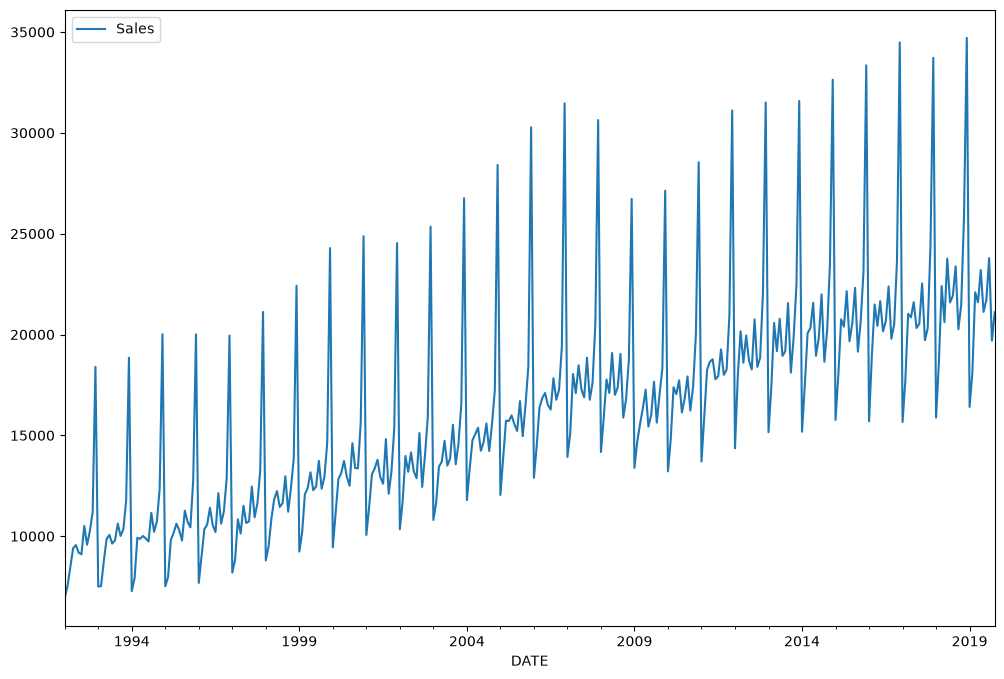

In [4]:
# Plot data penjualan
sales_data.plot(figsize=(12, 8))

### Pembagian dataset

18 bulan terakhir dijadikan data test, sisanya data train. Urutan waktu dipertahankan (data tidak diacak) karena urutan sangat penting pada time series.

In [5]:
# Train-test split
test_size = 18
test_index = len(sales_data) - test_size
train = sales_data.iloc[:test_index]
test = sales_data.iloc[test_index:]

## 3. Normalisasi Data

- **Inisialisasi MinMaxScaler**: untuk menskalakan data ke rentang 0–1.
- **`scaler.fit(train)`**: menghitung nilai minimum dan maksimum dari data latih.
- **`scaler.transform`**: mentransformasikan data train dan test ke skala yang telah dihitung.

In [6]:
# Inisialisasi MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(train)

# Transformasi data train dan test
scaled_train = scaler.transform(train)
scaled_test = scaler.transform(test)

## 4. Membuat Time Series Generator

- **Panjang sekuens**: `length = 12`, yaitu 12 bulan sebelumnya dipakai sebagai input.
- **`n_features = 1`**: hanya satu variabel (Sales).
- **Generator time series**: `TimeseriesGenerator` memisahkan input (X = 12 bulan) dan target (y = bulan berikutnya) dari data secara bergeser.

In [7]:
# Membuat generator data time series
length = 12 # Panjang input (12 bulan)
n_features = 1
generator = TimeseriesGenerator(scaled_train, scaled_train, length=length, batch_size=1)

## 5. Membangun Model RNN

- **Arsitektur**: `SimpleRNN` 100 unit (aktivasi ReLU), output `Dense(1)` untuk prediksi satu nilai.
- **Kompilasi**: optimizer `adam`, loss function `mse`.
- **Early Stopping**: hentikan pelatihan setelah 3 epoch tanpa peningkatan `val_loss`, lalu kembalikan bobot terbaik.
- **Validation generator**: dibuat dari data test untuk menghitung `val_loss`.
- **Pelatihan**: 20 epoch dengan validasi menggunakan `TimeseriesGenerator`.

In [8]:
# Model SimpleRNN
model_rnn = Sequential()
model_rnn.add(SimpleRNN(100, activation='relu', input_shape=(length, n_features)))
model_rnn.add(Dense(1))
model_rnn.compile(optimizer='adam', loss='mse')
model_rnn.summary()

# Callback early stopping untuk RNN
early_stop_rnn = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Validation generator
validation_generator = TimeseriesGenerator(scaled_test, scaled_test, length=length, batch_size=1)

# Melatih model RNN
history_rnn = model_rnn.fit(generator, epochs=20, validation_data=validation_generator, callbacks=[early_stop_rnn])

c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 100)            │        10,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,301 (40.24 KB)

 Trainable params: 10,301 (40.24 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0243 - val_loss: 0.0045
Epoch 2/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0097 - val_loss: 3.3974e-04
Epoch 3/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0024 - val_loss: 0.0019
Epoch 4/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0025 - val_loss: 3.0137e-04
Epoch 5/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0019 - val_loss: 0.0034
Epoch 6/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0024 - val_loss: 9.0503e-04
Epoch 7/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0013 - val_loss: 0.0011


## 5. Membangun Model LSTM

- **Arsitektur**: `LSTM` 100 unit (memiliki cell state serta forget, input, dan output gate), ditambah `Dropout(0.2)` untuk mengurangi overfitting, dan output `Dense(1)`.
- **Kompilasi**: optimizer Adam (learning rate 0.001), loss `mse`.
- **Early Stopping**: hentikan setelah 5 epoch tanpa peningkatan `val_loss`.
- **Pelatihan**: 20 epoch dengan validasi.

In [9]:
# Model LSTM dengan penambahan Dropout
model_lstm = Sequential()
model_lstm.add(LSTM(100, activation='relu', input_shape=(length, n_features)))
model_lstm.add(Dropout(0.2)) # Penambahan Dropout untuk mengurangi overfitting
model_lstm.add(Dense(1))
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_lstm.summary()

# Callback early stopping untuk LSTM
early_stop_lstm = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Melatih model LSTM
history_lstm = model_lstm.fit(generator, epochs=20, validation_data=validation_generator, callbacks=[early_stop_lstm])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100)            │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,901 (159.77 KB)

 Trainable params: 40,901 (159.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0276 - val_loss: 0.0072
Epoch 2/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0198 - val_loss: 0.0042
Epoch 3/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0148 - val_loss: 0.0024
Epoch 4/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0094 - val_loss: 0.0013
Epoch 5/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0046 - val_loss: 0.0019
Epoch 6/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0046 - val_loss: 0.0048
Epoch 7/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0038 - val_loss: 0.0017
Epoch 8/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0034 - val_loss: 4.4938e-04
Epoch 9/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0043 - val_loss: 0.0024
Epoch 10/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0035 - val_loss: 4.6694e-04
Epoch 11/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0027 - val_loss: 2.7708e-04
Epoch 12/20
304/304 ━━━━━━━━━━━━━━━━━━━━

## 6. Evaluasi Model dan Prediksi

**Fungsi untuk evaluasi loss**: `plot_loss` menyimpan training dan validation loss RNN & LSTM dari `history` ke DataFrame, lalu memvisualisasikannya per epoch dalam satu grafik untuk memantau overfitting atau underfitting.

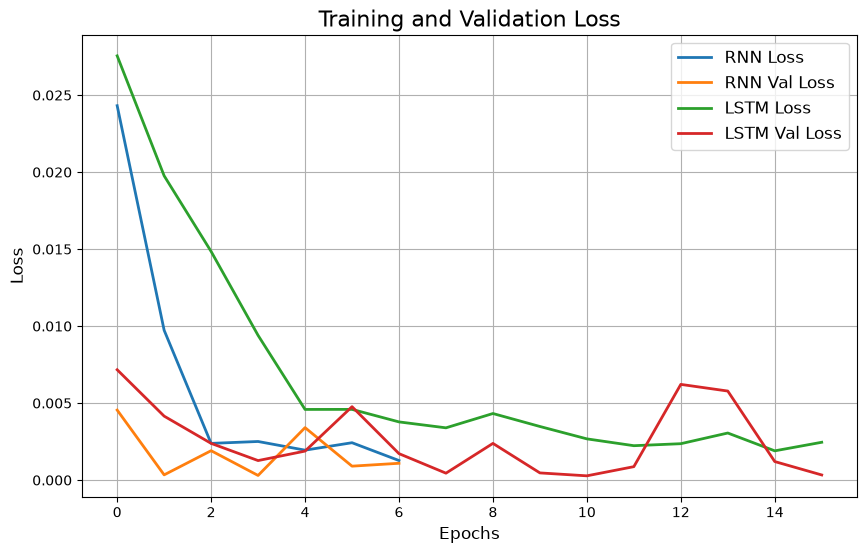

In [10]:
# Fungsi untuk plot training dan validation loss
def plot_loss(history_rnn, history_lstm):
    # Plot the training and validation loss
    losses_rnn = pd.DataFrame(history_rnn.history)
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss(history_rnn, history_lstm)

### Plot loss per model

Fungsi `plot_loss_rnn` dan `plot_loss_lstm` memvisualisasikan loss dan validation loss untuk masing-masing model secara terpisah.

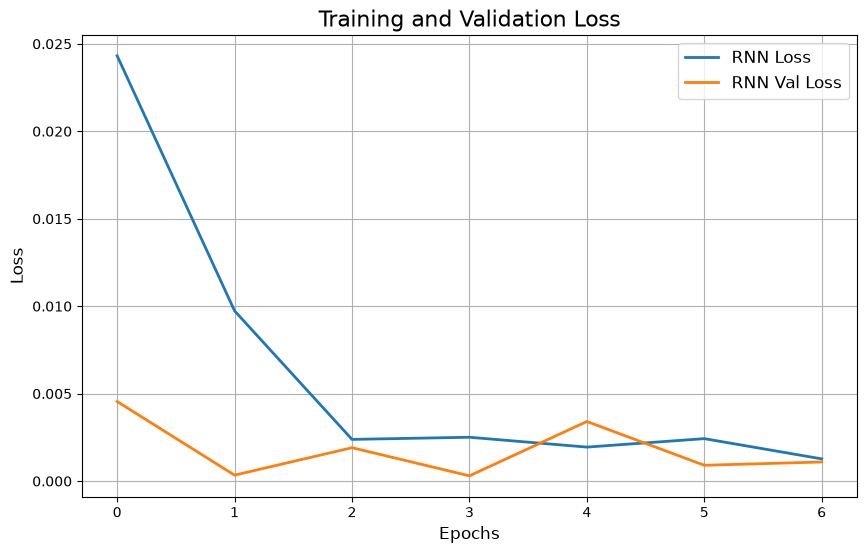

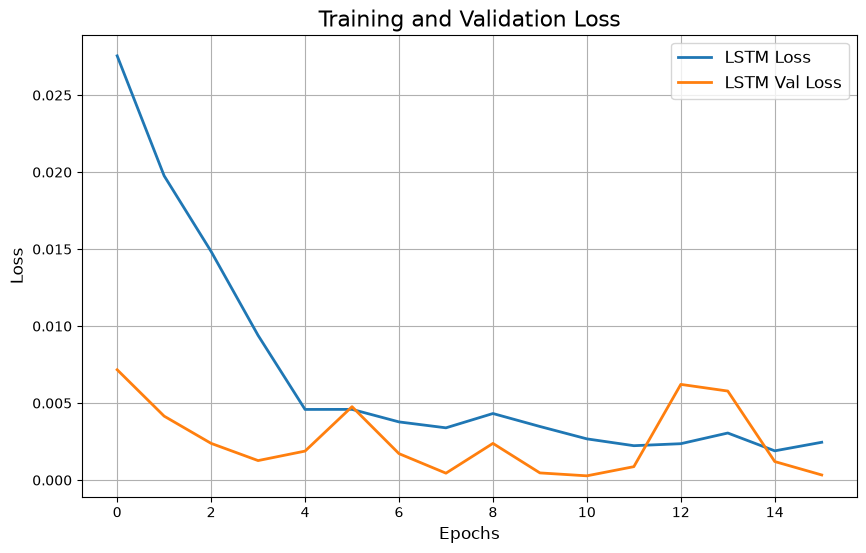

In [11]:
def plot_loss_rnn(history_rnn):
    # Plot the training and validation loss
    losses_rnn = pd.DataFrame(history_rnn.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

def plot_loss_lstm(history_lstm):
    # Plot the training and validation loss
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss_rnn(history_rnn)
plot_loss_lstm(history_lstm)

## 6. Prediksi Model dan Plot Prediksi

Fungsi `make_predictions` memprediksi data test secara berulang: dimulai dari 12 data terakhir train, memprediksi satu langkah ke depan, lalu hasil prediksi dimasukkan ke batch untuk prediksi berikutnya. Hasilnya dikembalikan ke skala asli dengan `scaler.inverse_transform` dan ditambahkan ke DataFrame `test`.

In [12]:
# Membuat prediksi untuk data test dengan RNN dan LSTM
def make_predictions(model, scaled_data, length, n_features):
    predictions = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(len(test)):
        current_pred = model.predict(current_batch)[0]
        predictions.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(predictions)

rnn_predictions = make_predictions(model_rnn, scaled_train, length, n_features)
lstm_predictions = make_predictions(model_lstm, scaled_train, length, n_features)

# Menambahkan prediksi ke dataframe test
test['RNN_Predictions'] = rnn_predictions
test['LSTM_Predictions'] = lstm_predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━

### Plot prediksi

Fungsi `plot_predictions` menampilkan penjualan aktual bersama prediksi RNN dan LSTM pada periode test, dengan sumbu-x diformat per 3 bulan.

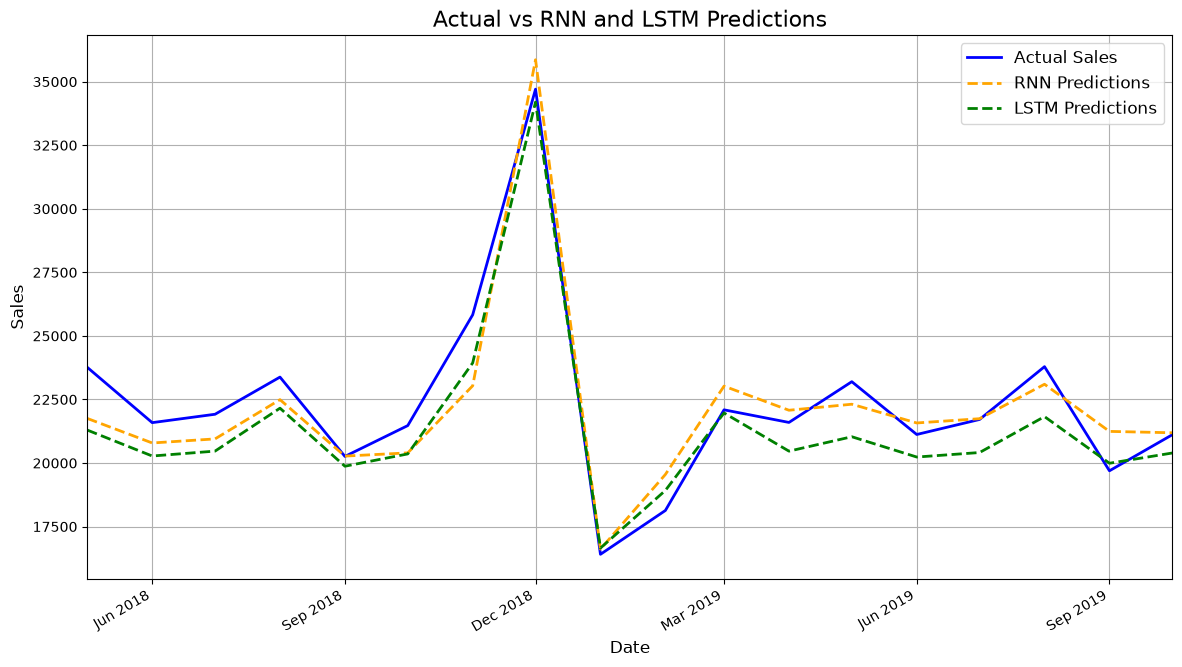

In [13]:
# Fungsi untuk plot prediksi RNN dan LSTM bersama data actual
def plot_predictions(test, sales_data, rnn_predictions, lstm_predictions):
    # Plot RNN and LSTM predictions along with actual sales
    plt.figure(figsize=(14, 8))
    plt.plot(test.index, test['Sales'], label='Actual Sales', color='blue', linewidth=2)
    plt.plot(test.index, test['RNN_Predictions'], label='RNN Predictions', color='orange', linestyle='--', linewidth=2)
    plt.plot(test.index, test['LSTM_Predictions'], label='LSTM Predictions', color='green', linestyle='--', linewidth=2)

    # Formatting the x-axis to show dates nicely
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gcf().autofmt_xdate() # Rotate the x labels for better readability

    plt.title('Actual vs RNN and LSTM Predictions', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.xlim([test.index[0], test.index[-1]])
    plt.show()

plot_predictions(test, sales_data, rnn_predictions, lstm_predictions)

## 7. Prediksi Jangka Panjang

Fungsi `forecast_future` memprediksi penjualan untuk 12 bulan ke depan dengan cara yang sama seperti `make_predictions`, tetapi jumlah langkahnya ditentukan oleh parameter `periods`. Hasil forecast RNN dan LSTM disimpan ke DataFrame dengan index tanggal bulanan mulai November 2019.

In [14]:
# Membuat prediksi ke depan dengan model
def forecast_future(model, scaled_data, length, n_features, periods):
    forecast = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(periods):
        current_pred = model.predict(current_batch)[0]
        forecast.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(forecast)

# Prediksi untuk 12 periode ke depan
forecast_rnn = forecast_future(model_rnn, scaled_train, length, n_features, periods=12)
forecast_lstm = forecast_future(model_lstm, scaled_train, length, n_features, periods=12)

# Membuat dataframe untuk forecast
forecast_index = pd.date_range(start='2019-11-01', periods=12, freq='MS')
forecast_rnn_data = pd.DataFrame(data=forecast_rnn, index=forecast_index, columns=['RNN_Forecast'])
forecast_lstm_data = pd.DataFrame(data=forecast_lstm, index=forecast_index, columns=['LSTM_Forecast'])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


## 7. Plot Forecast

Fungsi `plot_forecast`:
- Menyesuaikan indeks waktu forecast agar dimulai tepat setelah data aktual terakhir.
- Menambahkan nilai aktual terakhir sebagai titik awal prediksi, lalu menggabungkan data aktual dengan prediksi.
- Memvisualisasikan tren penjualan aktual dan forecast RNN & LSTM pada rentang Januari 2018 – Desember 2020.

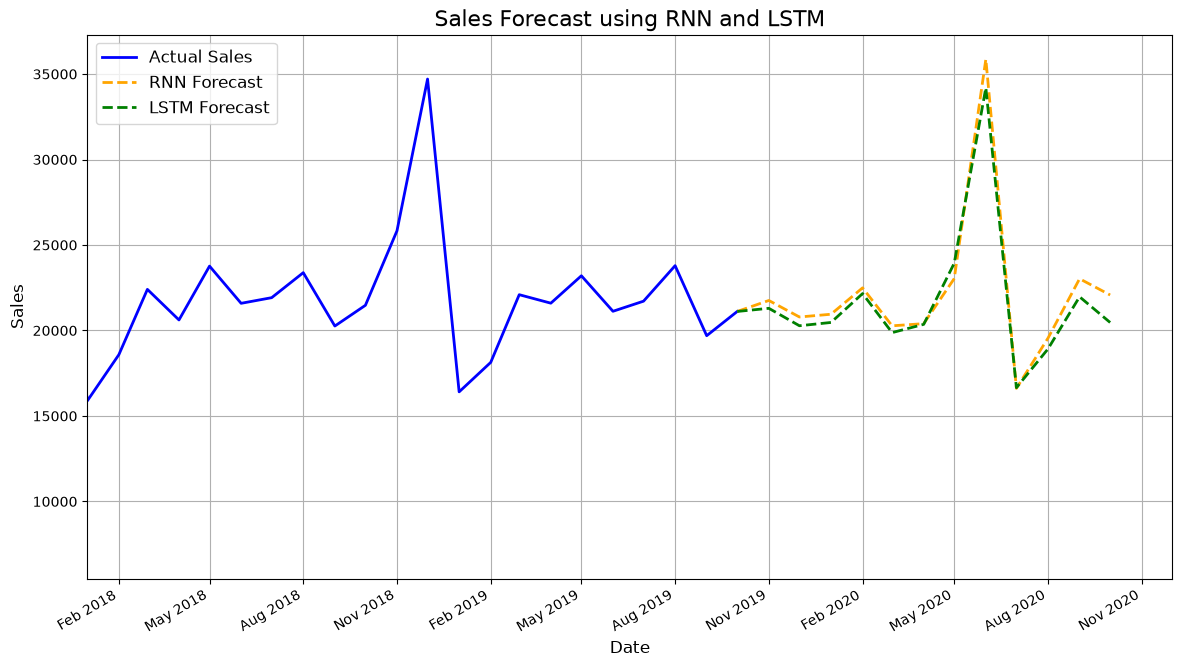

In [15]:
# Fungsi untuk plot forecast ke depan
def plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data):
    # Mendapatkan nilai dan index terakhir dari sales_data
    last_actual_value = sales_data['Sales'].iloc[-1]
    last_actual_date = sales_data.index[-1]

    # Menyusun prediksi agar dimulai tepat setelah data actual
    forecast_rnn_data.index = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=len(forecast_rnn_data), freq='MS')
    forecast_lstm_data.index = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=len(forecast_lstm_data), freq='MS')

    # Menambahkan nilai terakhir data actual sebagai titik awal prediksi
    forecast_rnn_data = pd.concat([pd.DataFrame({'RNN_Forecast': [last_actual_value]}, index=[last_actual_date]), forecast_rnn_data])
    forecast_lstm_data = pd.concat([pd.DataFrame({'LSTM_Forecast': [last_actual_value]}, index=[last_actual_date]), forecast_lstm_data])

    # Gabungkan data actual dan prediksi
    combined_rnn_data = pd.concat([sales_data, forecast_rnn_data], axis=0)
    combined_lstm_data = pd.concat([sales_data, forecast_lstm_data], axis=0)

    # Plot actual sales dan prediksi forecast
    plt.figure(figsize=(14, 8))

    # Plot actual sales
    plt.plot(sales_data.index, sales_data['Sales'], label='Actual Sales', color='blue', linewidth=2)

    # Plot RNN forecast
    plt.plot(forecast_rnn_data.index, forecast_rnn_data['RNN_Forecast'],
             label='RNN Forecast', color='orange', linestyle='--', linewidth=2)

    # Plot LSTM forecast
    plt.plot(forecast_lstm_data.index, forecast_lstm_data['LSTM_Forecast'],
             label='LSTM Forecast', color='green', linestyle='--', linewidth=2)

    # Set the limits for x-axis to control the date range
    plt.xlim(pd.to_datetime('2018-01-01'), pd.to_datetime('2020-12-01'))

    # Formatting the x-axis to show dates nicely
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))     # Show every 3 months
    plt.gcf().autofmt_xdate()

    plt.title('Sales Forecast using RNN and LSTM', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

# Contoh pemanggilan fungsi setelah model dijalankan
plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data)